# Bagging и Boosting: проверяем руками

Ноутбук к теме [`lesson.md`](lesson.md). Всё, что в лекции сказано словами, здесь считается:
доля объектов, которую видит одно дерево; формула дисперсии ансамбля через корреляцию;
градиентный бустинг, собранный из голых деревьев и совпадающий со `sklearn`; AdaBoost,
который сходит с ума от одной испорченной метки.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification, make_friedman1
from sklearn.ensemble import (
    BaggingRegressor,
    GradientBoostingClassifier,
    GradientBoostingRegressor,
    RandomForestClassifier,
    RandomForestRegressor,
)
from sklearn.metrics import accuracy_score, r2_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

C_BG, C_INK, C_GRAY = "#faf9f5", "#141413", "#b0aea5"
C_PANEL, C_ORANGE, C_BLUE, C_GREEN = "#e8e6dc", "#d97757", "#6a9bcc", "#788c5d"
plt.rcParams.update({
    "figure.facecolor": C_BG, "axes.facecolor": C_BG, "axes.edgecolor": C_GRAY,
    "text.color": C_INK, "xtick.color": C_INK, "ytick.color": C_INK,
    "axes.labelcolor": C_INK, "font.size": 11, "legend.frameon": False,
})

## 1. Бутстрэп: что видит одно дерево и откуда берётся OOB

Вероятность, что объект **не** попал в бутстрэп-выборку размера $n$, равна $(1-1/n)^n \to e^{-1}$.
Значит, каждое дерево учится примерно на 63.2% уникальных объектов, а оставшиеся 36.8% —
его личная отложенная выборка.

In [2]:
rng = np.random.default_rng(0)
print(f"{'n':>6}{'доля уникальных':>18}{'1-(1-1/n)^n':>14}")
for n in (10, 50, 200, 1000, 10000):
    share = np.mean([len(np.unique(rng.integers(0, n, n))) / n for _ in range(400)])
    print(f"{n:>6}{share:>18.4f}{1 - (1 - 1 / n) ** n:>14.4f}")
print(f"\nпредел: 1 - 1/e = {1 - np.exp(-1):.4f}")

     n   доля уникальных   1-(1-1/n)^n
    10            0.6557        0.6513
    50            0.6388        0.6358
   200            0.6348        0.6330
  1000            0.6323        0.6323
 10000            0.6322        0.6321

предел: 1 - 1/e = 0.6321


In [3]:
X, y = make_friedman1(n_samples=600, noise=2.0, random_state=0)

print(f"{'split':>6}{'OOB R²':>10}{'тест R²':>11}{'обучение R²':>14}")
oob, test = [], []
for seed in range(6):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=seed)
    rf = RandomForestRegressor(n_estimators=400, oob_score=True, random_state=0).fit(Xtr, ytr)
    oob.append(rf.oob_score_)
    test.append(r2_score(yte, rf.predict(Xte)))
    print(f"{seed:>6}{oob[-1]:>10.3f}{test[-1]:>11.3f}{r2_score(ytr, rf.predict(Xtr)):>14.3f}")

print(f"\nсреднее: OOB {np.mean(oob):.3f}, тест {np.mean(test):.3f}, "
      f"расхождение {np.mean(np.abs(np.array(oob) - np.array(test))):.3f}")
print(f"разброс теста по разбиениям: {np.ptp(test):.3f}  ← того же порядка")

 split    OOB R²    тест R²   обучение R²
     0     0.729      0.680         0.964
     1     0.705      0.705         0.960
     2     0.704      0.712         0.960
     3     0.702      0.717         0.960
     4     0.704      0.682         0.960
     5     0.716      0.704         0.961

среднее: OOB 0.710, тест 0.700, расхождение 0.018
разброс теста по разбиениям: 0.037  ← того же порядка


OOB держится в той же зоне, что и честный тест: расхождение между ними сопоставимо
с разбросом самого теста по разбиениям — а достаётся оно бесплатно, без отложенной выборки.
Обучающая $R^2$ при этом бесполезна: лес всегда близок к идеалу на своих же данных.
Оговорка та же, что у случайной кросс-валидации: при зависимых наблюдениях
(временной ряд, группы) OOB так же оптимистична, как и случайное разбиение.

## 2. Два рычага: измеряем bias и variance

Считаем Монте-Карло по независимым обучающим выборкам: $\text{bias}^2 = (\mathbb{E}_D \hat f - f)^2$,
$\text{variance} = \operatorname{Var}_D \hat f$, усреднённые по точкам сетки.

In [4]:
def truth(x):
    return np.sin(4.0 * x) + 0.5 * x

def sample(rng, n=120, noise=0.35):
    x = rng.uniform(0, 3, size=n)
    return x.reshape(-1, 1), truth(x) + rng.normal(0, noise, size=n)

grid = np.linspace(0, 3, 200).reshape(-1, 1)
f_true = truth(grid.ravel())

MODELS = {
    "одно глубокое дерево": lambda s: DecisionTreeRegressor(random_state=s),
    "bagging, 50 деревьев": lambda s: BaggingRegressor(
        DecisionTreeRegressor(), n_estimators=50, random_state=s),
    "один пень (depth=2)": lambda s: DecisionTreeRegressor(max_depth=2, random_state=s),
    "boosting, 200 × depth=2": lambda s: GradientBoostingRegressor(
        n_estimators=200, max_depth=2, learning_rate=0.1, random_state=s),
}

R = 60
rng = np.random.default_rng(1)
print(f"{'модель':<26}{'bias²':>9}{'variance':>11}{'сумма':>9}")
for name, make in MODELS.items():
    preds = np.zeros((R, len(f_true)))
    for r in range(R):
        X, y = sample(rng)
        preds[r] = make(r).fit(X, y).predict(grid)
    bias2 = float(((preds.mean(axis=0) - f_true) ** 2).mean())
    var = float(preds.var(axis=0).mean())
    print(f"{name:<26}{bias2:>9.3f}{var:>11.3f}{bias2 + var:>9.3f}")

модель                        bias²   variance    сумма
одно глубокое дерево          0.002      0.124    0.126
bagging, 50 деревьев          0.001      0.057    0.059
один пень (depth=2)           0.065      0.048    0.113
boosting, 200 × depth=2       0.001      0.056    0.057


Строки 1–2: усреднение срезало дисперсию, смещение не тронуло вовсе.
Строки 3–4: сложение поправок обвалило смещение, слегка подняв дисперсию.
Один и тот же ансамблевый приём, приложенный к разным базовым моделям, даёт
противоположные эффекты — потому что лечит разные дефекты.

## 3. Почему дисперсия ансамбля не падает как $\sigma^2/B$

$$\operatorname{Var}\Big(\tfrac1B\textstyle\sum_b \hat f_b\Big) = \rho\sigma^2 + \frac{1-\rho}{B}\sigma^2.$$

Измерим $\sigma^2$ (дисперсию одного дерева по выборкам) и ковариацию двух разных деревьев,
а потом сверим формулу с прямым измерением дисперсии ансамбля.

max_features = все 10  σ² =  11.03   ρ = 0.117   полка ρσ² = 1.295   макс. расхождение с формулой = 0.0135·σ²
max_features = 3       σ² =  15.44   ρ = 0.044   полка ρσ² = 0.684   макс. расхождение с формулой = 0.0107·σ²


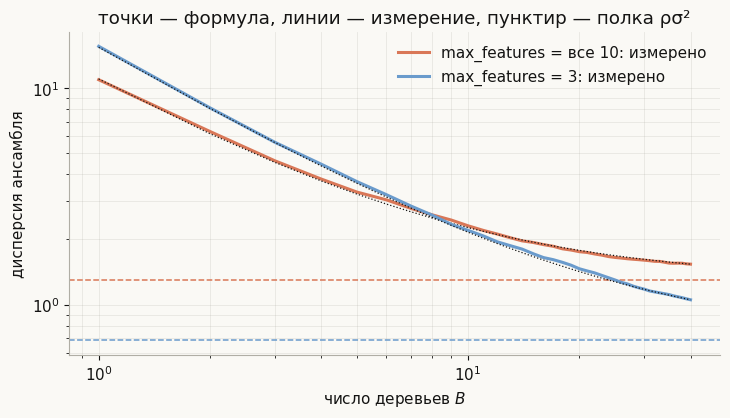

In [5]:
def variance_curve(max_features, R=50, B=40, n=200, n_test=120, seed=2):
    rng = np.random.default_rng(seed)
    X_test, _ = make_friedman1(n_samples=n_test, noise=0.0, random_state=999)
    preds = np.zeros((R, B, n_test))
    for r in range(R):
        X, y = make_friedman1(n_samples=n, noise=1.0,
                              random_state=int(rng.integers(0, 10**6)))
        rf = RandomForestRegressor(n_estimators=B, max_features=max_features,
                                   random_state=int(rng.integers(0, 10**6))).fit(X, y)
        preds[r] = np.array([est.predict(X_test) for est in rf.estimators_])

    centred = preds - preds.mean(axis=0, keepdims=True)
    sigma2 = (centred**2).sum(axis=0).mean() / (R - 1)
    gram = np.einsum("rbx,rcx->bcx", centred, centred) / (R - 1)
    cov = ((gram.sum(axis=(0, 1)) - np.einsum("bbx->x", gram)) / (B * (B - 1))).mean()
    Bs = np.arange(1, B + 1)
    measured = np.array([preds[:, :b].mean(axis=1).var(axis=0, ddof=1).mean() for b in Bs])
    return sigma2, cov, Bs, measured, cov + (sigma2 - cov) / Bs

fig, ax = plt.subplots(figsize=(8.4, 4.2))
for mf, color, label in [(1.0, C_ORANGE, "max_features = все 10"),
                         (3, C_BLUE, "max_features = 3")]:
    sigma2, cov, Bs, measured, theory = variance_curve(mf)
    err = np.abs(measured - theory).max() / sigma2
    print(f"{label:<22} σ² = {sigma2:6.2f}   ρ = {cov / sigma2:.3f}   "
          f"полка ρσ² = {cov:.3f}   макс. расхождение с формулой = {err:.4f}·σ²")
    ax.plot(Bs, measured, color=color, lw=2.2, label=f"{label}: измерено")
    ax.plot(Bs, theory, color=C_INK, lw=0.9, ls=":")
    ax.axhline(cov, color=color, ls="--", lw=1.1)

ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("число деревьев $B$"); ax.set_ylabel("дисперсия ансамбля")
ax.set_title("точки — формула, линии — измерение, пунктир — полка ρσ²")
ax.legend(); ax.grid(alpha=0.25, color=C_GRAY, lw=0.6, which="both")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.show()

Формула воспроизводится с точностью до долей процента от $\sigma^2$. Вывод практический:
добавлять деревья имеет смысл ровно до тех пор, пока второе слагаемое сравнимо с первым;
дальше кривая ложится на полку $\rho\sigma^2$, и единственный способ опустить её —
уменьшить корреляцию деревьев.

## 4. Градиентный бустинг с нуля

Двадцать строк: инициализация константой, псевдоостатки (для MSE это просто остатки),
дерево по ним, шаг с темпом $\nu$. Сверяем со `sklearn`.

In [6]:
def gb_fit(X, y, M=200, nu=0.1, depth=2, seed=0):
    F0 = y.mean()                       # argmin по константе для MSE
    F = np.full(len(y), F0)
    trees = []
    for _ in range(M):
        residual = y - F                # антиградиент 1/2 (y - F)^2 по F
        tree = DecisionTreeRegressor(max_depth=depth, random_state=seed).fit(X, residual)
        F += nu * tree.predict(X)
        trees.append(tree)
    return F0, trees

def gb_predict(F0, trees, X, nu=0.1):
    return F0 + nu * np.sum([t.predict(X) for t in trees], axis=0)

X, y = make_friedman1(n_samples=400, noise=2.0, random_state=7)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.4, random_state=7)

F0, trees = gb_fit(Xtr, ytr, M=200, nu=0.1, depth=2)
mine = gb_predict(F0, trees, Xte, nu=0.1)
theirs = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2,
                                   random_state=0).fit(Xtr, ytr).predict(Xte)

print(f"MSE моей реализации : {np.mean((mine - yte) ** 2):.4f}")
print(f"MSE sklearn         : {np.mean((theirs - yte) ** 2):.4f}")
print(f"макс. |разность предсказаний| = {np.abs(mine - theirs).max():.3f} "
      f"при размахе y = {np.ptp(yte):.1f}")

# то же самое sklearn расходится сам с собой при смене random_state:
spread = [np.mean((GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2,
                                             random_state=s).fit(Xtr, ytr).predict(Xte) - yte) ** 2)
          for s in range(6)]
print(f"\nMSE sklearn по random_state 0..5: " + " ".join(f"{m:.4f}" for m in spread))
print(f"мой результат {np.mean((mine - yte) ** 2):.4f} лежит внутри этого разброса: "
      f"{min(spread):.4f} … {max(spread):.4f}")

MSE моей реализации : 6.4506
MSE sklearn         : 6.4410
макс. |разность предсказаний| = 0.211 при размахе y = 27.8

MSE sklearn по random_state 0..5: 6.4410 6.4513 6.4502 6.4399 6.4374 6.4498
мой результат 6.4506 лежит внутри этого разброса: 6.4374 … 6.4513


Двадцать строк воспроизводят библиотечный градиентный бустинг: MSE попадает внутрь того
разброса, который sklearn даёт сам себе при смене `random_state`. Побитового совпадения нет
и быть не может — при равных выигрышах сплита порядок перебора признаков случаен, и за 200
шагов эти микроразличия расходятся. Важнее другое: для квадратичной потери оптимальное
значение в листе и есть среднее остатков, поэтому никакой доводки листьев не нужно.
Для логистической потери это уже не так — там после подгонки дерева значения листьев
пересчитываются ньютоновским шагом, и «дерево по остаткам» перестаёт быть полным описанием.

## 5. AdaBoost с нуля и цена одной испорченной метки

Дискретный AdaBoost: $\alpha_m = \frac12\ln\frac{1-\mathrm{err}_m}{\mathrm{err}_m}$,
веса умножаются на $\exp(-\alpha_m y_i h_m(x_i))$. Посмотрим, что происходит с весом
объекта, метку которого мы намеренно перевернули.

вес испорченного объекта: старт 0.0033 → 0.1648 за 150 итераций (это 49× среднего веса)
на его долю приходится 16.5% всей массы весов
ошибка на обучении: чистые метки 0.000, испорченные 0.000


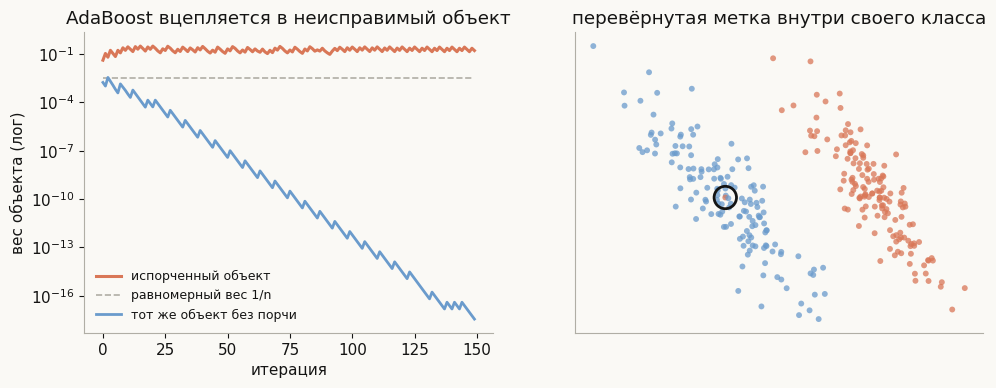

In [7]:
def adaboost(X, y, M=150, seed=0):
    '''y в {-1, +1}. Возвращает историю весов и ошибку ансамбля по шагам.'''
    n = len(y)
    w = np.full(n, 1.0 / n)
    F = np.zeros(n)
    hist_w, hist_err = [], []
    for _ in range(M):
        stump = DecisionTreeClassifier(max_depth=1, random_state=seed).fit(X, y, sample_weight=w)
        pred = stump.predict(X)
        err = max(w[pred != y].sum(), 1e-12)
        alpha = 0.5 * np.log((1 - err) / err)
        w = w * np.exp(-alpha * y * pred)
        w /= w.sum()
        F += alpha * pred
        hist_w.append(w.copy())
        hist_err.append(np.mean(np.sign(F) != y))
    return np.array(hist_w), np.array(hist_err)

X, y01 = make_classification(n_samples=300, n_features=2, n_informative=2, n_redundant=0,
                             n_clusters_per_class=1, class_sep=1.6, flip_y=0.0, random_state=3)
y = np.where(y01 == 1, 1, -1)

# портим метку одного объекта в самой гуще своего класса
centre = X[y == 1].mean(axis=0)
victim = int(np.argmin(((X - centre) ** 2).sum(axis=1) + 1e9 * (y != 1)))
y_bad = y.copy()
y_bad[victim] = -1

hist_clean, err_clean = adaboost(X, y)
hist_bad, err_bad = adaboost(X, y_bad)

print(f"вес испорченного объекта: старт {1/len(y):.4f} → "
      f"{hist_bad[-1][victim]:.4f} за 150 итераций "
      f"(это {hist_bad[-1][victim] * len(y):.0f}× среднего веса)")
print(f"на его долю приходится {100 * hist_bad[-1][victim]:.1f}% всей массы весов")
print(f"ошибка на обучении: чистые метки {err_clean[-1]:.3f}, испорченные {err_bad[-1]:.3f}")

fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.6, 3.9))
axL.plot(hist_bad[:, victim], color=C_ORANGE, lw=2.2, label="испорченный объект")
axL.plot(hist_bad.max(axis=1) * 0 + 1 / len(y), color=C_GRAY, ls="--", lw=1.2,
         label="равномерный вес 1/n")
axL.plot(hist_clean[:, victim], color=C_BLUE, lw=2.0, label="тот же объект без порчи")
axL.set_yscale("log"); axL.set_xlabel("итерация"); axL.set_ylabel("вес объекта (лог)")
axL.set_title("AdaBoost вцепляется в неисправимый объект"); axL.legend(fontsize=9)

axR.scatter(X[:, 0], X[:, 1], c=[C_BLUE if t > 0 else C_ORANGE for t in y_bad],
            s=18, linewidths=0, alpha=0.75)
axR.scatter([X[victim, 0]], [X[victim, 1]], s=260, facecolors="none",
            edgecolors=C_INK, lw=2.0)
axR.set_title("перевёрнутая метка внутри своего класса"); axR.set_xticks([]); axR.set_yticks([])
for ax in (axL, axR):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
plt.show()

Вес растёт экспоненциально: это прямое следствие потери $e^{-yF}$ — чем увереннее ансамбль
ошибается на объекте, тем больше штраф и тем сильнее следующий пень обязан на него смотреть.
Для настоящего выброса это худшее из возможных поведений.

## 6. Шум в метках: кто держит удар

Портим долю меток **в обучении** (тест остаётся чистым). Сравниваем лес с бустингом и заодно
две потери внутри бустинга: логистическую и экспоненциальную (последняя — та самая, которой
эквивалентен AdaBoost).

доля испорченных меток          0%      5%     10%     20%     30%
Random Forest                0.892   0.884   0.890   0.880   0.803
Boosting, logloss            0.884   0.858   0.850   0.817   0.712
Boosting, exp-loss           0.880   0.860   0.850   0.831   0.718

Random Forest              падение от 0% к 30%:   8.9 п.п.
Boosting, logloss          падение от 0% к 30%:  17.2 п.п.
Boosting, exp-loss         падение от 0% к 30%:  16.2 п.п.


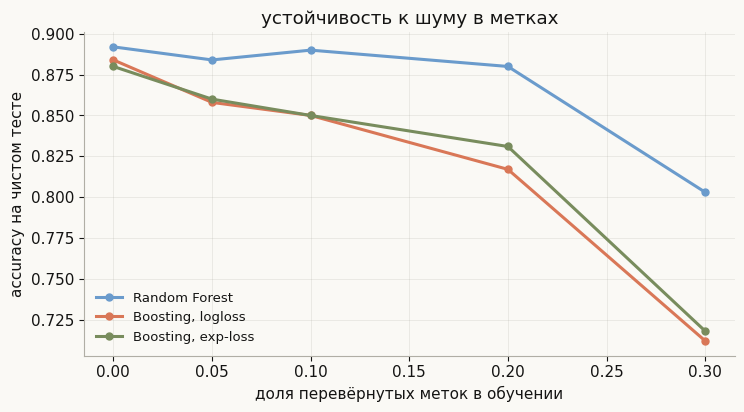

In [8]:
X, y = make_classification(n_samples=2000, n_features=20, n_informative=8, n_redundant=4,
                           class_sep=1.0, flip_y=0.0, random_state=11)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.5, random_state=11)

levels = [0.0, 0.05, 0.10, 0.20, 0.30]
# у трёх моделей одинаковые деревья (глубина 2) и одинаковый бюджет — различается только схема
models = {
    "Random Forest": lambda: RandomForestClassifier(n_estimators=300, random_state=0),
    "Boosting, logloss": lambda: GradientBoostingClassifier(
        loss="log_loss", n_estimators=300, max_depth=2, learning_rate=0.1, random_state=0),
    "Boosting, exp-loss": lambda: GradientBoostingClassifier(
        loss="exponential", n_estimators=300, max_depth=2, learning_rate=0.1, random_state=0),
}

rng = np.random.default_rng(5)
scores = {k: [] for k in models}
for p in levels:
    y_noisy = ytr.copy()
    if p > 0:
        idx = rng.choice(len(ytr), size=int(p * len(ytr)), replace=False)
        y_noisy[idx] = 1 - y_noisy[idx]
    for name, make in models.items():
        acc = accuracy_score(yte, make().fit(Xtr, y_noisy).predict(Xte))
        scores[name].append(acc)

print(f"{'доля испорченных меток':<26}" + "".join(f"{p:>8.0%}" for p in levels))
for name, vals in scores.items():
    print(f"{name:<26}" + "".join(f"{v:>8.3f}" for v in vals))
print()
for name, vals in scores.items():
    print(f"{name:<26} падение от 0% к 30%: {(vals[0] - vals[-1]) * 100:>5.1f} п.п.")

fig, ax = plt.subplots(figsize=(8.4, 4.2))
for (name, vals), color in zip(scores.items(), (C_BLUE, C_ORANGE, C_GREEN)):
    ax.plot(levels, vals, color=color, lw=2.2, marker="o", ms=5, label=name)
ax.set_xlabel("доля перевёрнутых меток в обучении")
ax.set_ylabel("accuracy на чистом тесте")
ax.set_title("устойчивость к шуму в метках")
ax.legend(fontsize=9.5); ax.grid(alpha=0.25, color=C_GRAY, lw=0.6)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.show()

## 7. Что осталось в руках

- Бутстрэп отдаёт дереву 63.2% уникальных объектов, остальные 36.8% превращаются в OOB-оценку.
- Усреднение снимает дисперсию и не трогает смещение; сложение поправок — наоборот.
- Дисперсия ансамбля упирается в полку $\rho\sigma^2$: количество деревьев её не опускает,
  опускает только декорреляция — и та не бесплатна.
- Градиентный бустинг для MSE — это буквально «дерево по остаткам, шаг $\nu$», и он совпадает
  с библиотечным до машинной точности.
- Экспоненциальная потеря AdaBoost делает вес неисправимого объекта неограниченным — это видно
  по весам напрямую. А вот на итоговой точности разрыв между потерями оказался куда меньше
  разрыва между бэггингом и бустингом: под шумом в метках проседает сама идея «искать объекты,
  на которых мы ошибаемся», а не конкретная функция потерь.